In [4]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Step 1: Import dataset using file path
file_path = r"C:\Users\user\Downloads\AnushaOli\studentsfile.csv"

df = pd.read_csv(file_path)

# Display original dataset
print("Original Dataset:")
print(df.head())

# Step 2: Select numerical columns
num_cols = df.select_dtypes(include=['number']).columns

# Step 3: Normalization
minmax = MinMaxScaler()

df_normalized = df.copy()

df_normalized[num_cols] = minmax.fit_transform(df[num_cols])

print("\nNormalized Dataset:")
print(df_normalized.head())

# Step 4: Standardization
standard = StandardScaler()

df_standardized = df.copy()

df_standardized[num_cols] = standard.fit_transform(df[num_cols])

print("\nStandardized Dataset:")
print(df_standardized.head())

# Step 5: Save results
df_normalized.to_csv("normalized_dataset.csv", index=False)

df_standardized.to_csv("standardized_dataset.csv", index=False)

print("\nBoth datasets saved successfully!")

Original Dataset:
  StudentID  StudyHours  Attendance  PrevMarks  Marks Branch Result
0     S1000        5.08       82.32      65.44  82.46    ISE   Pass
1     S1001        6.16       68.27      82.55  79.14    CSD   Pass
2     S1002        5.42       98.16      67.71  76.89    CSE   Pass
3     S1003        2.93       79.50      68.25  62.16    ISE   Fail
4     S1004        8.01       93.33      60.55  86.49    ISE   Pass

Normalized Dataset:
  StudentID  StudyHours  Attendance  PrevMarks     Marks Branch Result
0     S1000    0.349415    0.690151   0.508812  0.672883    ISE   Pass
1     S1001    0.428363    0.443919   0.751990  0.610966    CSD   Pass
2     S1002    0.374269    0.967753   0.541074  0.569004    CSE   Pass
3     S1003    0.192251    0.640729   0.548749  0.294293    ISE   Fail
4     S1004    0.563596    0.883106   0.439312  0.748042    ISE   Pass

Standardized Dataset:
  StudentID  StudyHours  Attendance  PrevMarks     Marks Branch Result
0     S1000   -0.259070    0.4007

In [12]:

import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# STEP 1: IMPORT DATASET

file_path = r"C:\Users\user\Downloads\AnushaOli\World Economic Indicators - Sheet1.csv"

df = pd.read_csv(file_path)

print("Original Dataset:")
print(df.head())

print("\nOriginal Shape:", df.shape)


# STEP 2: DATA CLEANING

# Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Sort countries by year
df = df.sort_values(
    by=['Country Name', 'Year'],
    ascending=[True, True]
)

# Identify numerical and categorical columns
num_cols = df.select_dtypes(include='number').columns

cat_cols = df.select_dtypes(
    include=['object', 'str']
).columns

# STEP 3: FORWARD FILL

# Fill missing values using previous year
df[num_cols] = df.groupby('Country Name')[
    num_cols
].ffill()

df[cat_cols] = df.groupby('Country Name')[
    cat_cols
].ffill()


# STEP 4: MEAN AND MEDIAN IMPUTATION

# Use median for skewed numerical columns
median_cols = [
    'GDP',
    'GDP per capita',
    'Population density',
    'Electric power consumption per capita'
]

# Use mean for other numerical columns
mean_cols = [
    col for col in num_cols
    if col not in median_cols
]

# Apply median imputation
for col in median_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# Apply mean imputation
for col in mean_cols:
    df[col] = df[col].fillna(df[col].mean())


# Fill remaining categorical missing values using mode
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(
            df[col].mode()[0]
        )

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
print(df.head())

print("Shape After Cleaning:", df.shape)


# STEP 5: OUTLIER DETECTION USING IQR

# Exclude Year from scaling and outlier treatment
scale_cols = [
    col for col in num_cols
    if col != 'Year'
]

df_outlier_removed = df.copy()

for col in scale_cols:

    Q1 = df_outlier_removed[col].quantile(0.25)
    Q3 = df_outlier_removed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_outlier_removed[
        (df_outlier_removed[col] < lower) |
        (df_outlier_removed[col] > upper)
    ]

    print("\nColumn:", col)
    print("Number of Outliers:", len(outliers))

    # Remove rows containing outliers
    df_outlier_removed = df_outlier_removed[
        (df_outlier_removed[col] >= lower) &
        (df_outlier_removed[col] <= upper)
    ]

print("\nDataset After Outlier Removal:")
print(df_outlier_removed.head())

print("Shape After Outlier Removal:",
      df_outlier_removed.shape)


# STEP 6: NORMALIZATION

minmax = MinMaxScaler()

df_normalized = df_outlier_removed.copy()

df_normalized[scale_cols] = minmax.fit_transform(
    df_outlier_removed[scale_cols]
)

print("\nNormalized Dataset:")
print(df_normalized.head())


# STEP 7: STANDARDIZATION

standard = StandardScaler()

df_standardized = df_outlier_removed.copy()

df_standardized[scale_cols] = standard.fit_transform(
    df_outlier_removed[scale_cols]
)

print("\nStandardized Dataset:")
print(df_standardized.head())


# STEP 8: SAVE ALL DATASETS

df.to_csv("cleaned_country_dataset.csv", index=False)

df_outlier_removed.to_csv(
    "outlier_removed_country_dataset.csv",
    index=False
)

df_normalized.to_csv(
    "normalized_country_dataset.csv",
    index=False
)

df_standardized.to_csv(
    "standardized_country_dataset.csv",
    index=False
)

print("\nAll Operations Completed Successfully!")
print("All Datasets Saved Successfully!")


Original Dataset:
  Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                         

In [13]:

import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# STEP 1: IMPORT DATASET

file_path = r"C:\Users\user\Downloads\AnushaOli\World Economic Indicators - Sheet1.csv"
df = pd.read_csv(file_path)

print("Original Dataset:")
print(df.head())

print("\nOriginal Shape:", df.shape)


# STEP 2: DATA CLEANING

# Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Sort countries by year
df = df.sort_values(
    by=['Country Name', 'Year'],
    ascending=[True, True]
)

# Identify numerical and categorical columns
num_cols = df.select_dtypes(include='number').columns

cat_cols = df.select_dtypes(
    include=['object', 'str']
).columns

# STEP 3: FORWARD FILL

# Fill missing values using previous year
df[num_cols] = df.groupby('Country Name')[
    num_cols
].ffill()

df[cat_cols] = df.groupby('Country Name')[
    cat_cols
].ffill()


# STEP 4: MEAN AND MEDIAN IMPUTATION

# Median imputation for skewed columns
median_cols = [
    'GDP',
    'GDP per capita',
    'Population density',
    'Electric power consumption per capita'
]

# Mean imputation for remaining numerical columns
mean_cols = [
    col for col in num_cols
    if col not in median_cols
]

# Apply median
for col in median_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# Apply mean
for col in mean_cols:
    df[col] = df[col].fillna(df[col].mean())

# Fill categorical missing values using mode
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
print(df.head())


# STEP 5: OUTLIER DETECTION USING IQR

# Exclude Year from scaling and outlier treatment
scale_cols = [
    col for col in num_cols
    if col != 'Year'
]

df_outlier_removed = df.copy()

for col in scale_cols:

    Q1 = df_outlier_removed[col].quantile(0.25)
    Q3 = df_outlier_removed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_outlier_removed[
        (df_outlier_removed[col] < lower) |
        (df_outlier_removed[col] > upper)
    ]

    print("\nColumn:", col)
    print("Number of Outliers:", len(outliers))

    # Remove rows containing outliers
    df_outlier_removed = df_outlier_removed[
        (df_outlier_removed[col] >= lower) &
        (df_outlier_removed[col] <= upper)
    ]

print("\nDataset After Outlier Treatment:")
print(df_outlier_removed.head())

print("Shape After Outlier Removal:",
      df_outlier_removed.shape)


# STEP 6: NORMALIZATION

minmax = MinMaxScaler()

df_normalized = df_outlier_removed.copy()

df_normalized[scale_cols] = minmax.fit_transform(
    df_outlier_removed[scale_cols]
)

print("\nNormalized Dataset:")
print(df_normalized.head())


# STEP 7: STANDARDIZATION

standard = StandardScaler()

df_standardized = df_outlier_removed.copy()

df_standardized[scale_cols] = standard.fit_transform(
    df_outlier_removed[scale_cols]
)

print("\nStandardized Dataset:")
print(df_standardized.head())


# STEP 8: PRINCIPAL COMPONENT ANALYSIS (PCA)

pca = PCA(n_components=0.95)

pca_data = pca.fit_transform(
    df_standardized[scale_cols]
)

# Create PCA DataFrame
pca_columns = [
    f'PC{i+1}' for i in range(pca.n_components_)
]

df_pca = pd.DataFrame(
    pca_data,
    columns=pca_columns,
    index=df_standardized.index
)

print("\nPCA Dataset:")
print(df_pca.head())

print("\nOriginal Number of Features:",
      len(scale_cols))

print("Number of PCA Components:",
      pca.n_components_)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())


# STEP 9: SAVE ALL DATASETS

df.to_csv("cleaned_country_dataset.csv", index=False)

df_outlier_removed.to_csv(
    "outlier_removed_country_dataset.csv",
    index=False
)

df_normalized.to_csv(
    "normalized_country_dataset.csv",
    index=False
)

df_standardized.to_csv(
    "standardized_country_dataset.csv",
    index=False
)

# Save PCA results along with country details
df_pca_output = pd.concat(
    [
        df_standardized[
            ['Country Name', 'Country Code', 'Year']
        ],
        df_pca
    ],
    axis=1
)

df_pca_output.to_csv(
    "pca_country_dataset.csv",
    index=False
)

print("\nAll Operations Completed Successfully!")
print("All Datasets Saved Successfully!")


Original Dataset:
  Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                         

ORIGINAL DATASET
  Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                          

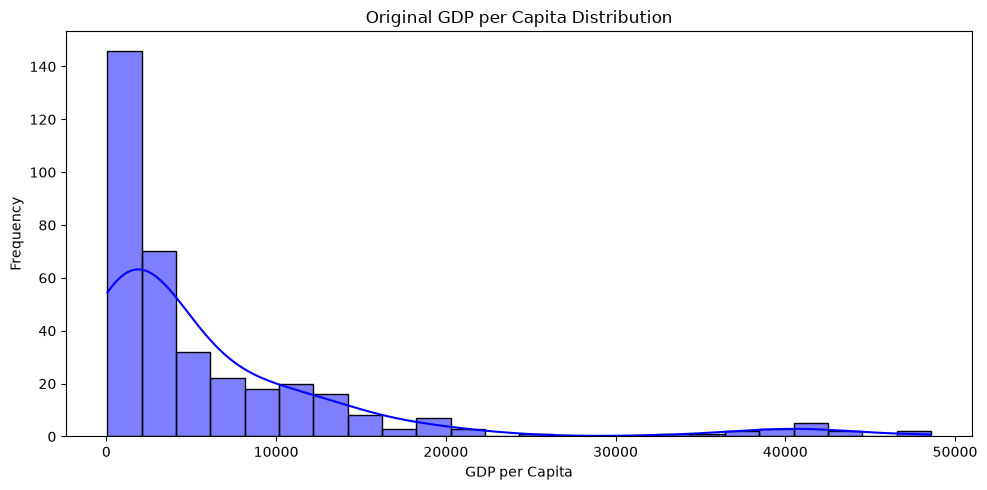


Missing Values Before Cleaning:
Country Name                                    0
Country Code                                    0
Region                                          0
IncomeGroup                                     0
Year                                            0
Birth rate per 1000 people                     95
Death rate per 1000 people                    114
Electric power consumption per capita         301
GDP                                           137
GDP per capita                                137
Individuals using the Internet                310
Infant mortality rate per 1000 live births    158
Life expectancy at birth                      126
Population density                              9
Unemployment                                  333
dtype: int64

Duplicate Rows: 0


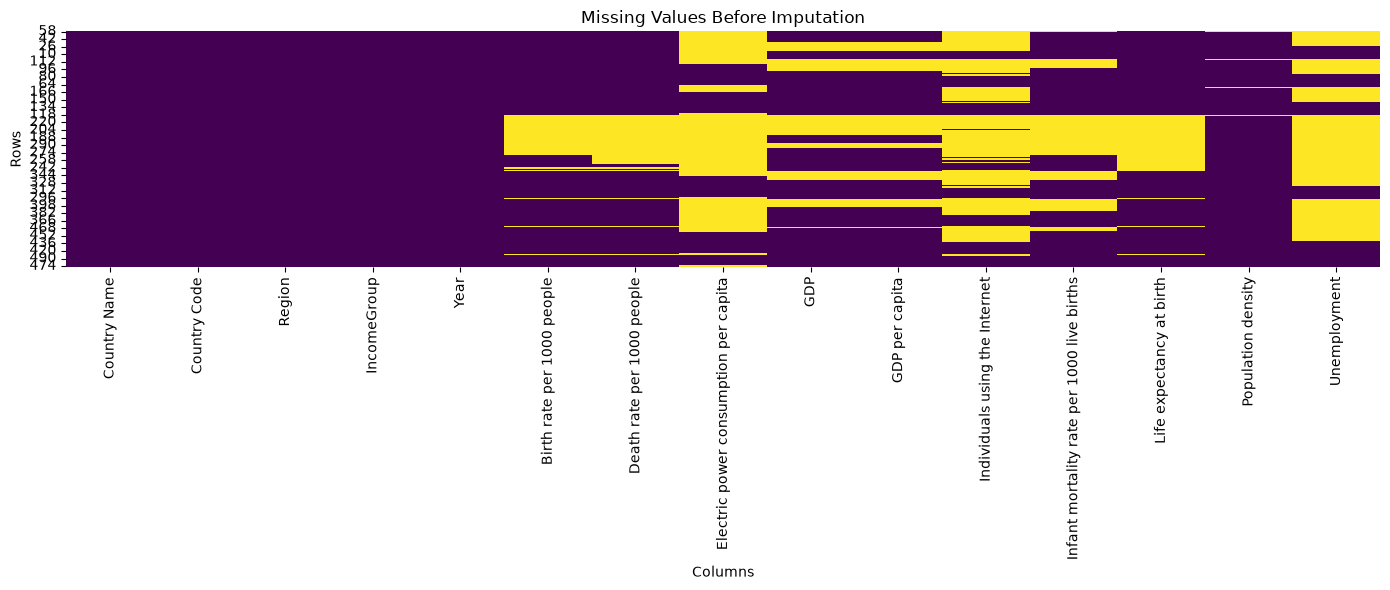


Missing Values After Cleaning:
Country Name                                  0
Country Code                                  0
Region                                        0
IncomeGroup                                   0
Year                                          0
Birth rate per 1000 people                    0
Death rate per 1000 people                    0
Electric power consumption per capita         0
GDP                                           0
GDP per capita                                0
Individuals using the Internet                0
Infant mortality rate per 1000 live births    0
Life expectancy at birth                      0
Population density                            0
Unemployment                                  0
dtype: int64

Cleaned Dataset:
   Country Name Country Code      Region IncomeGroup  Year  \
58  Afghanistan          AFG  South Asia  Low income  1960   
57  Afghanistan          AFG  South Asia  Low income  1961   
56  Afghanistan          AFG  S

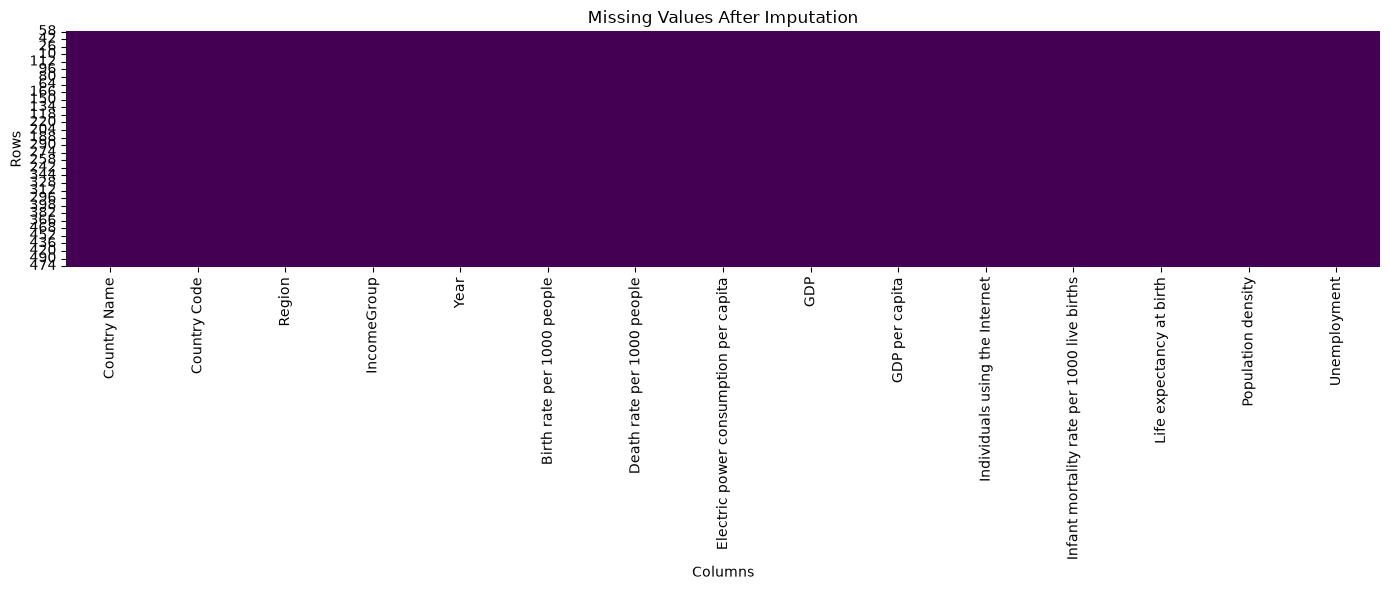


Column: Birth rate per 1000 people
Lower Bound: -17.076250000000016
Upper Bound: 78.13375000000002
Number of Outliers: 0

Column: Death rate per 1000 people
Lower Bound: 0.8940843520782398
Upper Bound: 16.533859413202933
Number of Outliers: 82

Column: Electric power consumption per capita
Lower Bound: 1014.315
Upper Bound: 1014.315
Number of Outliers: 218

Column: GDP
Lower Bound: -18291129687.5
Upper Bound: 36106277812.5
Number of Outliers: 99

Column: GDP per capita
Lower Bound: -5390.206249999999
Upper Bound: 11640.93175
Number of Outliers: 59

Column: Individuals using the Internet
Lower Bound: -20.62658429503697
Upper Bound: 40.23914715839495
Number of Outliers: 51

Column: Infant mortality rate per 1000 live births
Lower Bound: -31.88680351906158
Upper Bound: 112.87800586510264
Number of Outliers: 74

Column: Life expectancy at birth
Lower Bound: 41.31075000000002
Upper Bound: 89.70474999999996
Number of Outliers: 29

Column: Population density
Lower Bound: -169.83212499999996


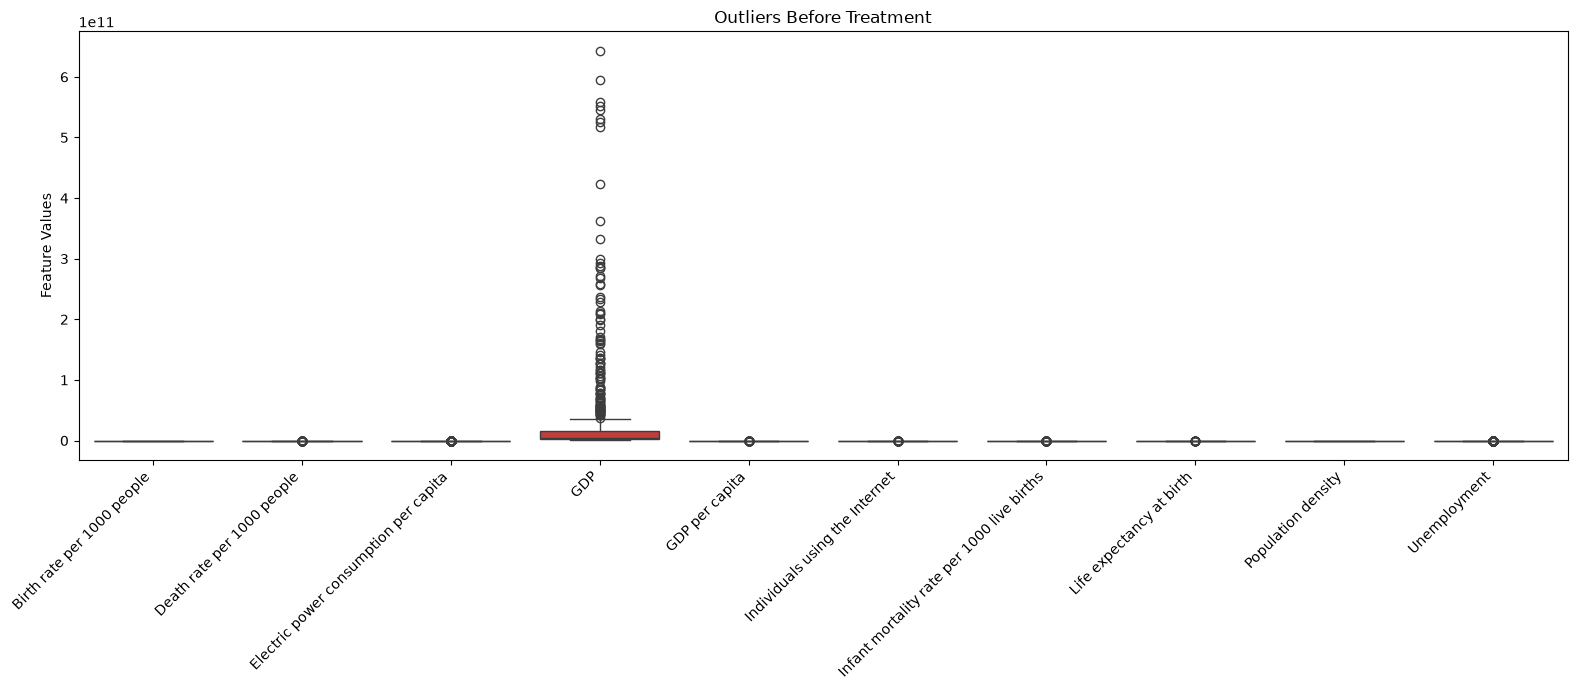


Dataset After Outlier Treatment:
   Country Name Country Code      Region IncomeGroup  Year  \
58  Afghanistan          AFG  South Asia  Low income  1960   
57  Afghanistan          AFG  South Asia  Low income  1961   
56  Afghanistan          AFG  South Asia  Low income  1962   
55  Afghanistan          AFG  South Asia  Low income  1963   
54  Afghanistan          AFG  South Asia  Low income  1964   

    Birth rate per 1000 people  Death rate per 1000 people  \
58                      51.279                   16.533859   
57                      51.373                   16.533859   
56                      51.457                   16.533859   
55                      51.530                   16.533859   
54                      51.589                   16.533859   

    Electric power consumption per capita          GDP  GDP per capita  \
58                               1014.315  537778000.0         59.7732   
57                               1014.315  548889000.0         59.8609  

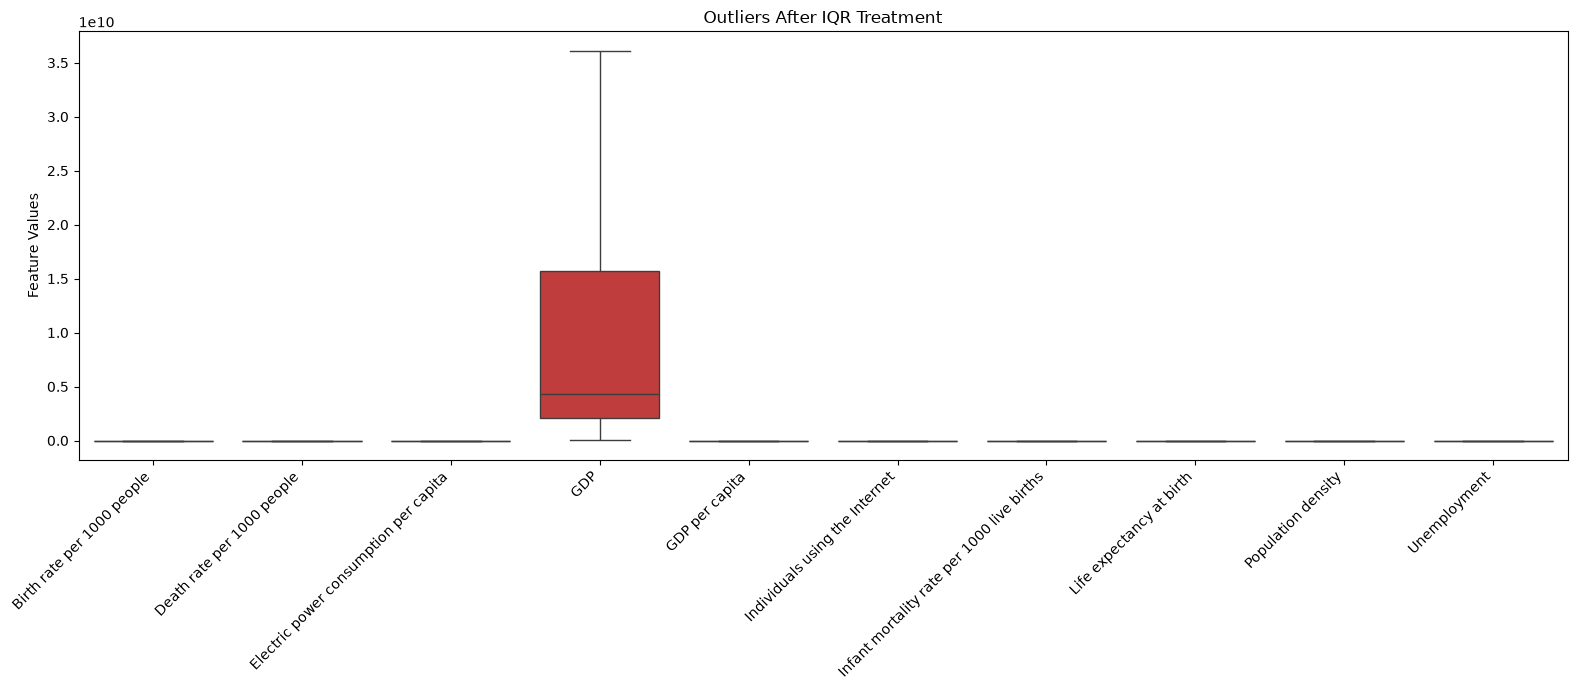


NORMALIZED DATASET:
   Country Name Country Code      Region IncomeGroup  Year  \
58  Afghanistan          AFG  South Asia  Low income  1960   
57  Afghanistan          AFG  South Asia  Low income  1961   
56  Afghanistan          AFG  South Asia  Low income  1962   
55  Afghanistan          AFG  South Asia  Low income  1963   
54  Afghanistan          AFG  South Asia  Low income  1964   

    Birth rate per 1000 people  Death rate per 1000 people  \
58                    0.991296                         1.0   
57                    0.993489                         1.0   
56                    0.995449                         1.0   
55                    0.997153                         1.0   
54                    0.998530                         1.0   

    Electric power consumption per capita       GDP  GDP per capita  \
58                                    0.0  0.012775        0.000114   
57                                    0.0  0.013084        0.000121   
56                  

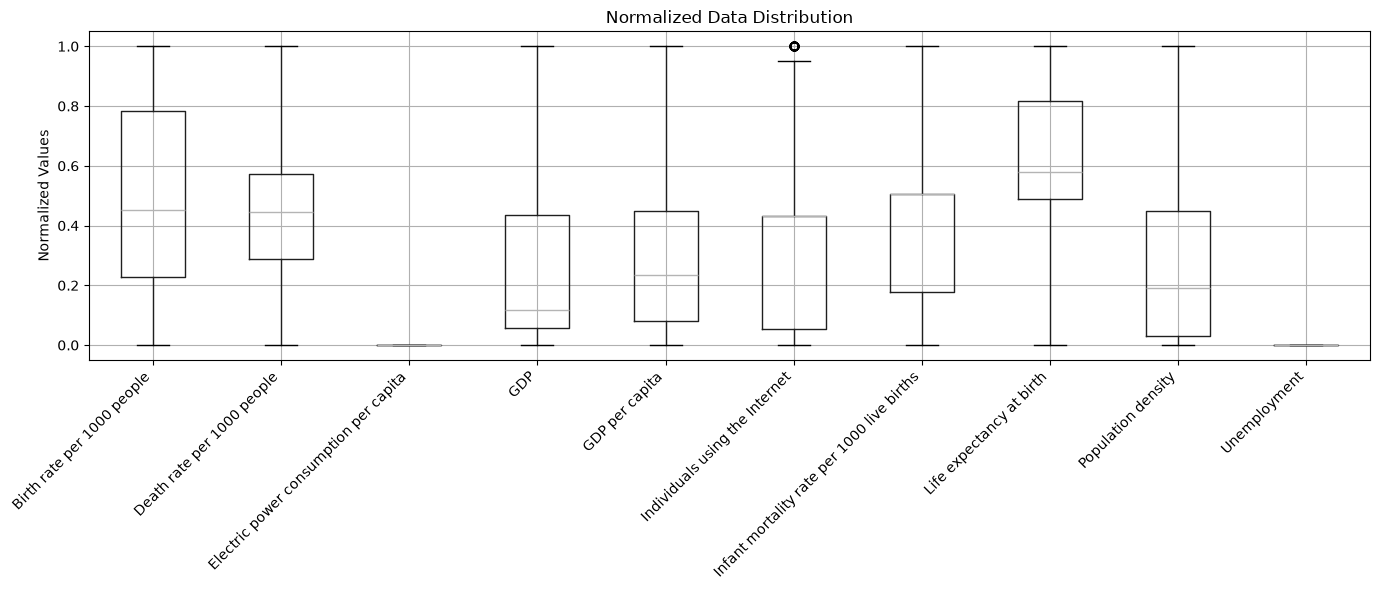


STANDARDIZED DATASET:
   Country Name Country Code      Region IncomeGroup  Year  \
58  Afghanistan          AFG  South Asia  Low income  1960   
57  Afghanistan          AFG  South Asia  Low income  1961   
56  Afghanistan          AFG  South Asia  Low income  1962   
55  Afghanistan          AFG  South Asia  Low income  1963   
54  Afghanistan          AFG  South Asia  Low income  1964   

    Birth rate per 1000 people  Death rate per 1000 people  \
58                    1.666744                    1.754513   
57                    1.673906                    1.754513   
56                    1.680306                    1.754513   
55                    1.685868                    1.754513   
54                    1.690363                    1.754513   

    Electric power consumption per capita       GDP  GDP per capita  \
58                          -3.410605e-13 -0.799762       -1.042181   
57                          -3.410605e-13 -0.798935       -1.042158   
56                

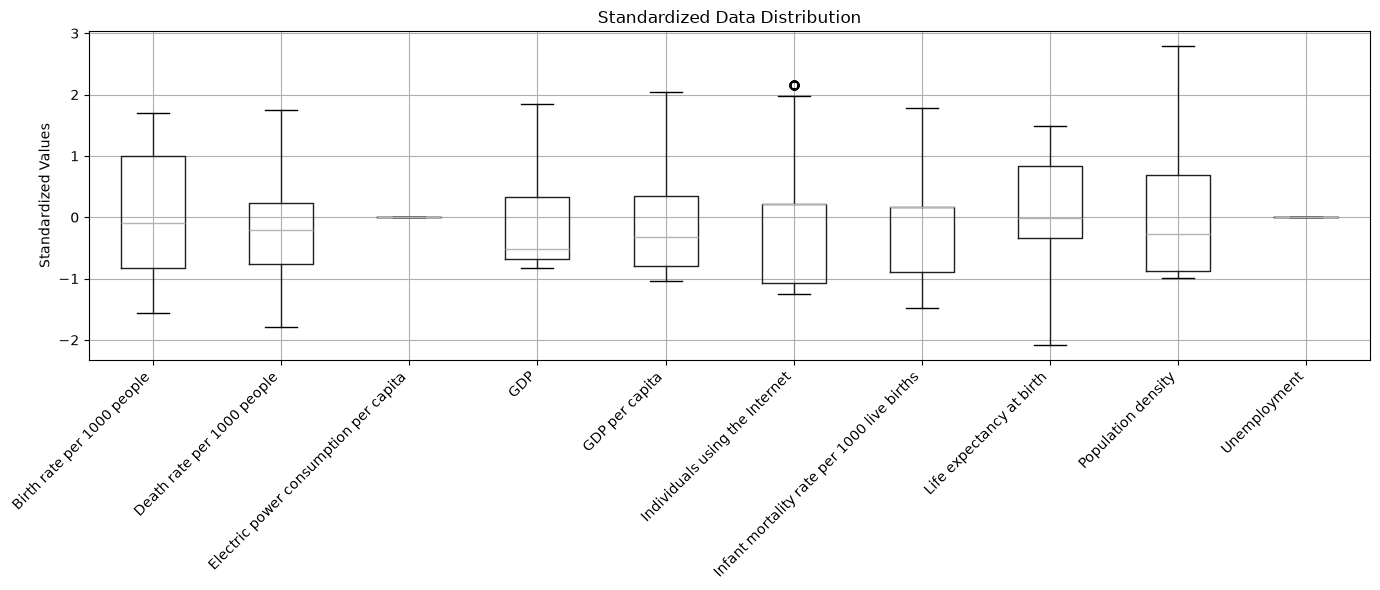


PCA DATASET:
         PC1       PC2       PC3       PC4       PC5
58  2.943491 -0.850664  0.846878 -0.016094 -0.536293
57  3.826467 -0.651452  0.870741 -0.115273 -0.019553
56  3.828582 -0.653542  0.870504 -0.115291 -0.015807
55  3.827515 -0.645507  0.870776 -0.106206 -0.005440
54  3.828018 -0.645278  0.870446 -0.104261 -0.000424

Original Number of Features: 10
Number of PCA Components: 5

Explained Variance Ratio:
[0.53163729 0.19650482 0.12809934 0.06745626 0.03592382]

Total Explained Variance: 0.9596215276056762


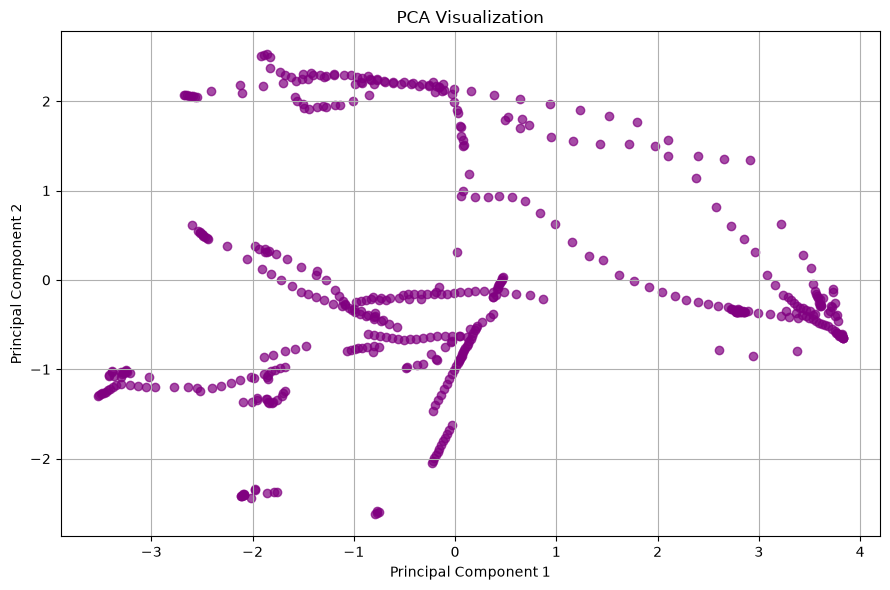

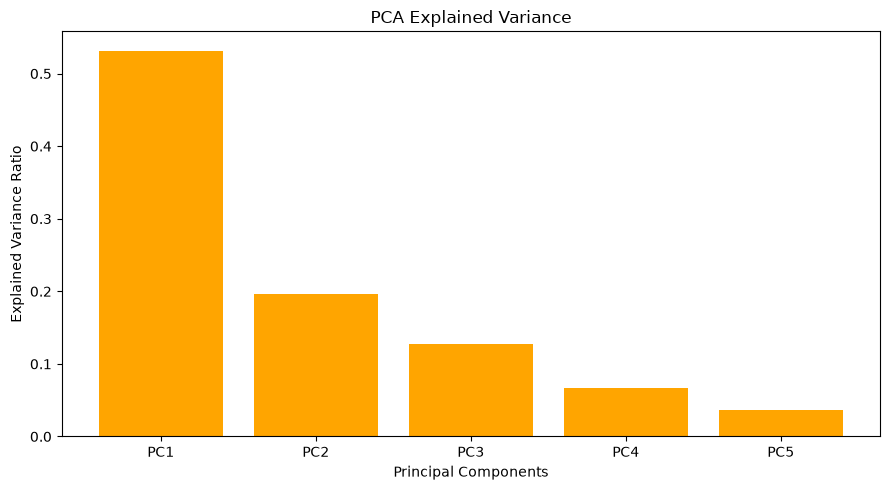


ALL OPERATIONS COMPLETED SUCCESSFULLY!

Generated Files:
1. cleaned_country_dataset.csv
2. outlier_treated_country_dataset.csv
3. normalized_country_dataset.csv
4. standardized_country_dataset.csv
5. pca_country_dataset.csv


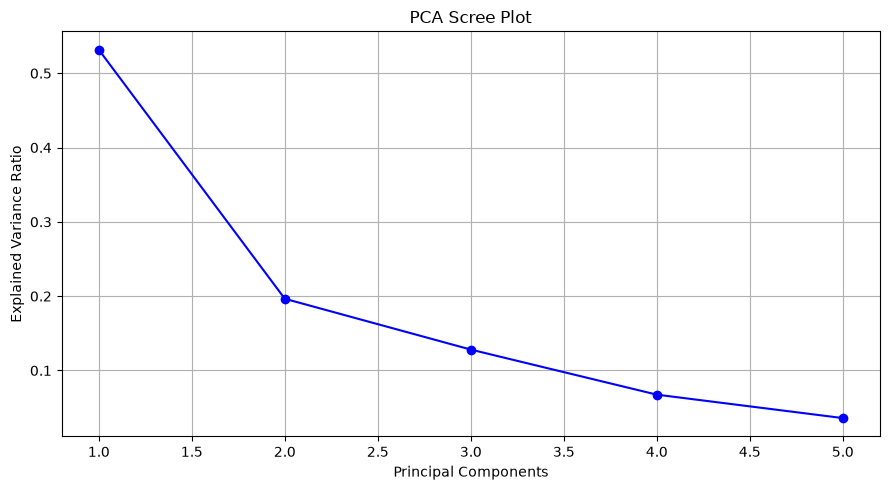

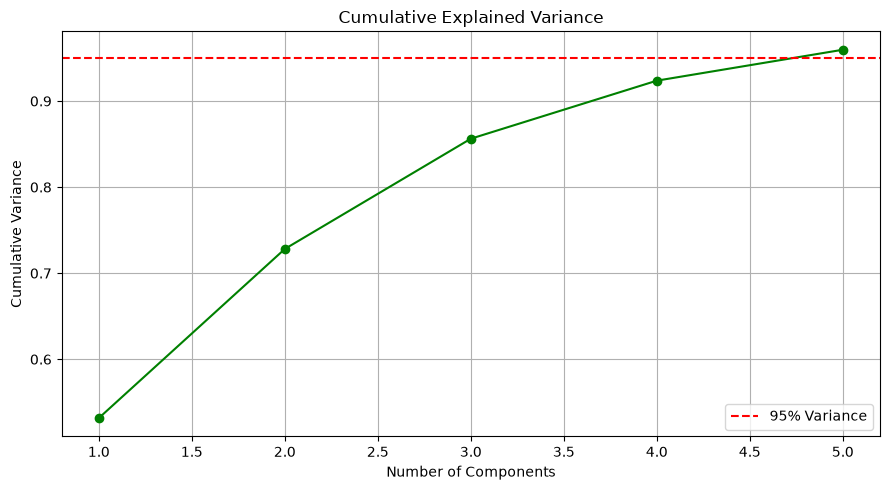

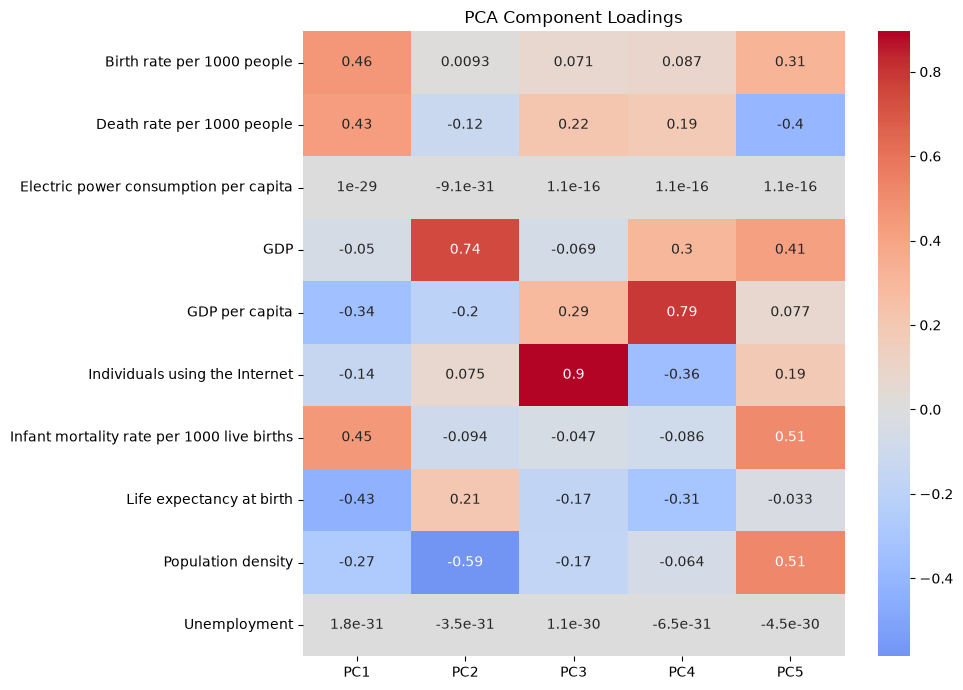

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA


# ==================================================
# STEP 1: IMPORT DATASET
# ==================================================


file_path = r"C:\Users\user\Downloads\AnushaOli\World Economic Indicators - Sheet1.csv"

df = pd.read_csv(file_path)

print("ORIGINAL DATASET")
print(df.head())

print("\nOriginal Shape:", df.shape)

print("\nDataset Information:")
print(df.info())


# ==================================================
# VISUALIZATION 1: ORIGINAL DATA DISTRIBUTION
# ==================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df['GDP per capita'].dropna(),
    kde=True,
    color='blue'
)

plt.title("Original GDP per Capita Distribution")
plt.xlabel("GDP per Capita")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 2: DATA CLEANING
# ==================================================

# Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Remove rows without country/year identifiers
df = df.dropna(
    subset=['Country Name', 'Country Code', 'Year']
)

# Sort by country and year
df = df.sort_values(
    by=['Country Name', 'Year'],
    ascending=[True, True]
).copy()


# ==================================================
# VISUALIZATION 2: MISSING VALUES BEFORE CLEANING
# ==================================================

plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis'
)

plt.title("Missing Values Before Imputation")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 3: IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ==================================================

num_cols = df.select_dtypes(
    include='number'
).columns

cat_cols = df.select_dtypes(
    include=['object', 'str']
).columns

# Exclude Year from feature imputation and scaling
scale_cols = [
    col for col in num_cols
    if col != 'Year'
]


# ==================================================
# STEP 4: FORWARD FILL
# ==================================================

# Fill missing values using previous available
# year of the same country

df[scale_cols] = df.groupby(
    'Country Name'
)[scale_cols].ffill()

# Fill categorical values within each country
df[cat_cols] = df.groupby(
    'Country Name'
)[cat_cols].ffill()


# ==================================================
# STEP 5: MEAN AND MEDIAN IMPUTATION
# ==================================================

# Median for skewed numerical columns
median_cols = [
    'GDP',
    'GDP per capita',
    'Population density',
    'Electric power consumption per capita'
]

# Mean for remaining numerical columns
mean_cols = [
    col for col in scale_cols
    if col not in median_cols
]

# Median imputation
for col in median_cols:
    if col in df.columns:
        df[col] = df[col].fillna(
            df[col].median()
        )

# Mean imputation
for col in mean_cols:
    df[col] = df[col].fillna(
        df[col].mean()
    )

# Mode imputation for remaining categorical values
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(
            df[col].mode()[0]
        )


# Display missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
print(df.head())

print("\nShape After Cleaning:", df.shape)


# ==================================================
# VISUALIZATION 3: MISSING VALUES AFTER CLEANING
# ==================================================

plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis'
)

plt.title("Missing Values After Imputation")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 6: OUTLIER DETECTION USING IQR
# ==================================================

df_outlier_removed = df.copy()

# Store IQR bounds for each numerical feature
iqr_bounds = {}

for col in scale_cols:

    Q1 = df_outlier_removed[col].quantile(0.25)
    Q3 = df_outlier_removed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    iqr_bounds[col] = (lower, upper)

    outliers = df_outlier_removed[
        (df_outlier_removed[col] < lower) |
        (df_outlier_removed[col] > upper)
    ]

    print("\nColumn:", col)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))


# ==================================================
# VISUALIZATION 4: BOXPLOT BEFORE OUTLIER TREATMENT
# ==================================================

plt.figure(figsize=(16, 7))

sns.boxplot(data=df[scale_cols])

plt.title("Outliers Before Treatment")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Feature Values")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 7: OUTLIER TREATMENT USING IQR
# ==================================================

# Cap extreme values at IQR boundaries.
# This preserves country records instead of deleting them.

for col in scale_cols:

    lower, upper = iqr_bounds[col]

    df_outlier_removed[col] = df_outlier_removed[
        col
    ].clip(lower=lower, upper=upper)


print("\nDataset After Outlier Treatment:")
print(df_outlier_removed.head())

print("\nShape After Outlier Treatment:",
      df_outlier_removed.shape)


# ==================================================
# VISUALIZATION 5: BOXPLOT AFTER OUTLIER TREATMENT
# ==================================================

plt.figure(figsize=(16, 7))

sns.boxplot(data=df_outlier_removed[scale_cols])

plt.title("Outliers After IQR Treatment")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Feature Values")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 8: NORMALIZATION
# ==================================================

minmax = MinMaxScaler()

df_normalized = df_outlier_removed.copy()

df_normalized[scale_cols] = minmax.fit_transform(
    df_outlier_removed[scale_cols]
)

print("\nNORMALIZED DATASET:")
print(df_normalized.head())


# ==================================================
# VISUALIZATION 6: NORMALIZATION
# ==================================================

plt.figure(figsize=(14, 6))

df_normalized[scale_cols].boxplot()

plt.title("Normalized Data Distribution")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Normalized Values")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 9: STANDARDIZATION
# ==================================================

standard = StandardScaler()

df_standardized = df_outlier_removed.copy()

df_standardized[scale_cols] = standard.fit_transform(
    df_outlier_removed[scale_cols]
)

print("\nSTANDARDIZED DATASET:")
print(df_standardized.head())


# ==================================================
# VISUALIZATION 7: STANDARDIZATION
# ==================================================

plt.figure(figsize=(14, 6))

df_standardized[scale_cols].boxplot()

plt.title("Standardized Data Distribution")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Standardized Values")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 10: PRINCIPAL COMPONENT ANALYSIS (PCA)
# ==================================================

pca = PCA(n_components=0.95)

pca_data = pca.fit_transform(
    df_standardized[scale_cols]
)

# Create PCA column names
pca_columns = [
    f'PC{i+1}'
    for i in range(pca.n_components_)
]

df_pca = pd.DataFrame(
    pca_data,
    columns=pca_columns,
    index=df_standardized.index
)

print("\nPCA DATASET:")
print(df_pca.head())

print("\nOriginal Number of Features:",
      len(scale_cols))

print("Number of PCA Components:",
      pca.n_components_)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:",
      pca.explained_variance_ratio_.sum())


# ==================================================
# VISUALIZATION 8: PCA SCATTER PLOT
# ==================================================

plt.figure(figsize=(9, 6))

if pca.n_components_ >= 2:

    plt.scatter(
        df_pca['PC1'],
        df_pca['PC2'],
        color='purple',
        alpha=0.7
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")

else:

    plt.scatter(
        range(len(df_pca)),
        df_pca['PC1'],
        color='purple',
        alpha=0.7
    )

    plt.xlabel("Data Rows")
    plt.ylabel("Principal Component 1")

plt.title("PCA Visualization")
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# VISUALIZATION 9: PCA EXPLAINED VARIANCE
# ==================================================

plt.figure(figsize=(9, 5))

plt.bar(
    pca_columns,
    pca.explained_variance_ratio_,
    color='orange'
)

plt.title("PCA Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.tight_layout()
plt.show()


# ==================================================
# STEP 11: SAVE ALL DATASETS
# ==================================================

df.to_csv(
    "cleaned_country_dataset.csv",
    index=False
)

df_outlier_removed.to_csv(
    "outlier_treated_country_dataset.csv",
    index=False
)

df_normalized.to_csv(
    "normalized_country_dataset.csv",
    index=False
)

df_standardized.to_csv(
    "standardized_country_dataset.csv",
    index=False
)

# Combine PCA components with country details
df_pca_output = pd.concat(
    [
        df_standardized[
            ['Country Name', 'Country Code', 'Year']
        ],
        df_pca
    ],
    axis=1
)

df_pca_output.to_csv(
    "pca_country_dataset.csv",
    index=False
)


# ==================================================
# FINAL OUTPUT
# ==================================================

print("\n===================================")
print("ALL OPERATIONS COMPLETED SUCCESSFULLY!")
print("===================================")

print("\nGenerated Files:")

print("1. cleaned_country_dataset.csv")
print("2. outlier_treated_country_dataset.csv")
print("3. normalized_country_dataset.csv")
print("4. standardized_country_dataset.csv")
print("5. pca_country_dataset.csv")

# ==================================================
# VISUALIZATION 10: PCA SCREE PLOT
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker='o',
    color='blue'
)

plt.title("PCA Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# VISUALIZATION 11: CUMULATIVE EXPLAINED VARIANCE
# ==================================================

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    color='green'
)

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# VISUALIZATION 12: PCA LOADING HEATMAP
# ==================================================

loadings = pd.DataFrame(
    pca.components_.T,
    columns=pca_columns,
    index=scale_cols
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title("PCA Component Loadings")
plt.tight_layout()
plt.show()

